# Lesson 6 — Attention by hand

**Your result:** a Transformer encoder layer written with plain tensor operations. It will match the encoder blocks inside the installed ACT model, for both outputs and gradients.

Five short exercises build it from the inside out: scaled attention with a padding mask, heads, multi-head attention, positions, then the layer. A larger experiment uses your layer to learn from real, padded action chunks. 

**Sources.** The equations follow [Attention Is All You Need](https://arxiv.org/abs/1706.03762), sections 3.1–3.5: encoder layer (3.1), scaled dot-product and multi-head attention (3.2), feed-forward (3.3), positional encoding (3.5). ACT uses this block in its [paper](https://arxiv.org/abs/2304.13705); its code is in `lerobot/policies/act/modeling_act.py` at the pinned revision `e0d50211ef236143ae867228662b7dfaba554f02`.

**You need** Python and NumPy. PyTorch is explained as it appears. Run from any folder inside this repository. Full answers are in [the reference notebook](06-act-attention-reference.ipynb). Three things stay separate: *your code* (cells you write), the *package reference* (`vla_lab.teaching.attention`, used here only as an oracle in checks), and the *installed LeRobot ACT blocks* (the pinned upstream code).

# Before you code

This course assumes strong Python skills and basic machine-learning knowledge. We explain PyTorch when it first appears. Read each shape, unit, mask, and parameter definition before you run the check. The reference copy gives a complete solution; the learner copy leaves the implementation for you.

Attention lets one token combine information from other tokens. Scaled dot-product attention is:

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\left(\frac{QK^{\top}}{\sqrt{D_h}}+M\right)V$$

Where:
* $Q\in\mathbb{R}^{B\times H\times T_q\times D_h}$ - queries: what each of the $T_q$ query tokens looks for.
* $K\in\mathbb{R}^{B\times H\times T_k\times D_h}$ - keys: what each of the $T_k$ key tokens offers.
* $V\in\mathbb{R}^{B\times H\times T_k\times D_h}$ - values: what each key token passes on when it is read.
* $B$ - batch size; $H$ - number of heads; $D_h$ - features per head.
* $M\in\mathbb{R}^{B\times H\times T_q\times T_k}$ - additive mask: allowed query-key pairs add 0, blocked pairs add $-\infty$ before the softmax.
* $\operatorname{softmax}$ - normalizes each row over the key axis so its weights sum to 1.

The output has shape $(B,H,T_q,D_h)$.

Numerical example: one query $q=[1,0]$, two keys $k_1=[1,0]$ and $k_2=[0,1]$, and $D_h=2$ give scores $[1/\sqrt{2},\,0]$. Softmax gives weights of about $[0.67,\,0.33]$, so the output is $0.67\,v_1+0.33\,v_2$. A padding mask blocks padded action tokens in the posterior. Camera position encodings tell the encoder which image-grid cell produced each visual token. The exercises use PyTorch tensors, linear layers, and matrix multiplication; every shape below describes one of these token axes.


In [ ]:
import os
import sys
from collections.abc import Sequence

# Supplied: workspace, offline caches, imports
from pathlib import Path

from vla_lab.teaching.blocks import EncoderParts, ProjectedAttention, ScaledAttention
from vla_lab.teaching.records import TrialConfig, TrialResult


def find_root() -> Path:
    for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (path / "manifests" / "act_references.yaml").is_file():
            return path
    raise FileNotFoundError("Start Jupyter inside the repository tree.")


WORKSPACE = find_root()
if str(WORKSPACE / "src") not in sys.path:
    sys.path.insert(0, str(WORKSPACE / "src"))

# Set cache paths and offline mode before any data or model library is imported.
os.environ["HF_HUB_CACHE"] = str(WORKSPACE / ".local-data/hf/hub")
os.environ["HF_DATASETS_CACHE"] = str(WORKSPACE / ".local-data/hf/datasets")
os.environ["HF_HUB_OFFLINE"] = "1"
os.environ["HF_DATASETS_OFFLINE"] = "1"
os.environ.setdefault("TORCH_HOME", str(WORKSPACE / ".local-data/torch"))
CONFIGS, DATA = WORKSPACE / "configs", WORKSPACE / ".local-data"
import math

import ipywidgets as widgets
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from IPython.display import display
from lerobot.policies.act.configuration_act import ACTConfig
from lerobot.policies.act.modeling_act import (
    ACTEncoder,
    ACTEncoderLayer,
    create_sinusoidal_pos_embedding,
)
from torch import nn

import vla_lab.teaching.attention as ref  # package reference: used by checks only
from vla_lab.teaching.diffusion import load_state_action_windows

torch.manual_seed(0)
print("PyTorch:", torch.__version__)
print("Workspace:", WORKSPACE)

PyTorch: 2.11.0+cu128
Workspace: /home/michal/code/vlas_tutorial


In [ ]:
# Supplied: a helper that the checks use
def close(actual: torch.Tensor, expected: torch.Tensor, message: str, atol: float = 1e-5) -> None:
    """Compare two tensors and say what failed."""
    assert actual.shape == expected.shape, (
        f"{message}: shape {tuple(actual.shape)}, expected {tuple(expected.shape)}"
    )
    worst = (actual.detach() - expected.detach()).abs().max().item()
    assert worst <= atol, f"{message}: largest difference {worst:.2e} is above {atol:.0e}"

## PyTorch notes

- A tensor has a **shape**, such as `(B, T, D)` = batch, positions, features. Most mistakes are shape mistakes. Print `x.shape` often.
- **Broadcasting** lets `(B, 1, 1, Tk)` combine with `(B, H, Tq, Tk)`. A size-1 axis repeats.
- `x.masked_fill(mask, value)` writes `value` where `mask` is `True`. `softmax(dim=-1)` normalizes over the last axis.
- `transpose(a, b)` swaps two axes without copying. After `transpose`, use `reshape`, not `view`.
- `loss.backward()` fills `.grad` on every tensor created with `requires_grad=True`. Padding must receive zero gradient.
- `module.train()` enables dropout. `module.eval()` disables it. The checks below use `eval()` or zero dropout.

## Visual experiment — change the padding mask

For a key padding mask with shape `(B, Tk)`, `True` means the key is blocked because it is padding. `False` means the key is allowed. Before softmax, the attention code sets each blocked score to negative infinity. Softmax runs across the key axis for each query row, so each allowed row sums to 1 and each blocked key receives weight 0. In the plot, blue means allowed and gray means blocked. The right panel shows the weights when all allowed scores are equal. The slider changes only this drawing; it does not run training or update model weights.


In [ ]:
# Visual only: show allowed and blocked keys, plus row-wise softmax weights.


def show_padding_mask(valid_keys: int = 5) -> None:
    key_count, query_count = 8, 4
    key_padding_mask = torch.arange(key_count) >= valid_keys  # True means blocked padding.
    allowed = (~key_padding_mask)[None, :].expand(query_count, -1)
    scores = torch.zeros(query_count, key_count).masked_fill(~allowed, -torch.inf)
    weights = torch.softmax(scores, dim=-1)  # Normalize across keys for each query row.

    figure, axes = plt.subplots(1, 2, figsize=(10, 3))
    axes[0].imshow(allowed.float(), cmap="Blues", vmin=0, vmax=1, aspect="auto")
    axes[0].set_title("Allowed key positions")
    axes[0].set_xlabel("Key position")
    axes[0].set_ylabel("Query row")
    axes[0].set_xticks(range(key_count))
    axes[1].imshow(weights, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    axes[1].set_title("Weights after row softmax")
    axes[1].set_xlabel("Key position")
    axes[1].set_ylabel("Query row")
    axes[1].set_xticks(range(key_count))
    figure.tight_layout()
    plt.show()


valid_key_slider = widgets.IntSlider(value=5, min=1, max=8, step=1, description="Real keys")
display(widgets.interactive(show_padding_mask, valid_keys=valid_key_slider))

interactive(children=(IntSlider(value=5, description='Real keys', max=8, min=1), Output()), _dom_classes=('wid…

**Real data used in this unit.** The cells below read real LIBERO `bowl_plate` demonstrations from local files
(no download starts here). Each *window* is 16 consecutive actions (7 values each). A window that runs past the end of an
episode repeats the last action and sets `is_pad=True` for those steps. The converted dataset declares a 10 FPS storage label. We select consecutive frame offsets. This label does not establish physical recording intervals, and it does not change the 20 Hz controller or cause action repetition. If the files are missing, the cell tells you the one setup command.

In [ ]:
# Supplied: real padded action windows (train and validation episodes are kept apart)
def read_windows(split: str) -> dict[str, torch.Tensor]:
    return load_state_action_windows(
        CONFIGS,
        DATA,
        "bowl_plate",
        split,
        horizon=16,
        n_obs_steps=1,
        action_start=0,
        drop_n_last_frames=0,
    )


TRAIN, VALID = read_windows("train"), read_windows("validation")
padded_counts = VALID["action_is_pad"].sum(1)
EXAMPLE = int((padded_counts == 6).nonzero()[0])  # a window whose last 6 steps are padding
example_actions = VALID["action"][EXAMPLE]  # (16, 7), scaled to [-1, 1]
example_pad = VALID["action_is_pad"][EXAMPLE]  # (16,), True for padding
print("train windows:", len(TRAIN["action"]), "validation windows:", len(VALID["action"]))
print("example window padding:", example_pad.int().tolist())

train windows: 3661 validation windows: 902
example window padding: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1]


## Exercise 6.1 — Scaled dot-product attention with a padding mask

**Purpose.** Write the one function that every Transformer block calls. It decides how much each query reads from each key.

**Contract (shapes, units, masks).**

- `query`: `(B, H, Tq, Dh)`; `key`, `value`: `(B, H, Tk, Dh)`. `B` batch, `H` heads, `T*` positions, `Dh` features per head.
- `key_padding_mask`: `(B, Tk)` bool or `None`. **`True` means padding**: that key must get weight exactly 0.
- Return `(output, weights)`: `output (B, H, Tq, Dh)` and `weights (B, H, Tq, Tk)`. Each row of `weights` sums to 1 over the real keys.
- A query row whose keys are all padding returns zero weights and zero output. It must not contain `nan`, and its gradient must be finite.
- `dropout_p`: probability of dropping attention weights in training. You may ignore it here; later modules pass 0 in evaluation.

**Method and source.** [Vaswani et al. 2017](https://arxiv.org/abs/1706.03762), section 3.2.1:

$$\operatorname{Attention}(Q,K,V)=\operatorname{softmax}\!\left(\frac{QK^{\top}}{\sqrt{D_h}}\right)V$$

Where $Q$, $K$, $V$ are `query`, `key`, `value`, and $D_h$ is the last axis of `query`. Padded keys are blocked before the softmax.

**Pointers.** Get all query–key scores with one matrix product. Scale them. Remove padded keys. Normalize over the key axis (the last one). Then take the weighted sum of values. Do not call torch's attention helpers: the check uses them as an oracle, and they do not return the weights you need.

<details><summary>Detailed hint</summary>

`scores = query @ key.transpose(-2, -1) / math.sqrt(Dh)` has shape `(B, H, Tq, Tk)`.
`blocked = key_padding_mask[:, None, None, :]` broadcasts over heads and queries.
Fill blocked scores with `torch.finfo(scores.dtype).min` (a large negative but finite number), then `softmax(dim=-1)`.
A row that is entirely blocked now has equal weights; set blocked positions of `weights` to 0 with `masked_fill(blocked, 0.0)` so that row becomes all zero.
Optional dropout: `F.dropout(weights, p=dropout_p, training=True)` on the weights, just before multiplying by `value`; return the weights without dropout.

</details>

More behaviour checks for this exercise: `check_scaled_dot_product_attention` in [lesson06_checks.py](lesson06_checks.py).

In [18]:
# Implement: Exercise 6.1
def scaled_dot_product_attention(
    query: torch.Tensor,
    key: torch.Tensor,
    value: torch.Tensor,
    key_padding_mask: torch.Tensor | None = None,
    dropout_p: float = 0.0,
) -> tuple[torch.Tensor, torch.Tensor]:
    # query (B,H,Tq,Dh); key,value (B,H,Tk,Dh); key_padding_mask (B,Tk) with True = padding.
    # Return (output (B,H,Tq,Dh), weights (B,H,Tq,Tk)).
    B, H, Tq, Dh = query.shape
    Dh = query.shape[-1]
    scores = (query @ key.transpose(-1, -2)) / math.sqrt(Dh)
    if key_padding_mask is not None:
        blocked = key_padding_mask[:, None, None, :]
        scores = scores.masked_fill(blocked, -torch.inf)

    weights = scores.softmax(dim=-1)
    if key_padding_mask is not None:
        weights = weights.masked_fill(blocked, 0.0)

    return weights @ value, weights


# Check: Exercise 6.1
torch.manual_seed(1)
B_, H_, Tq, Tk, Dh = 3, 4, 5, 6, 8
q, k, v = (torch.randn(B_, H_, n, Dh, requires_grad=True) for n in (Tq, Tk, Tk))
pad = torch.zeros(B_, Tk, dtype=torch.bool)
pad[1, 4:] = True
pad[2, 2:] = True
out, weights = scaled_dot_product_attention(q, k, v, pad)
assert out.shape == (B_, H_, Tq, Dh) and weights.shape == (B_, H_, Tq, Tk), (
    "Return (output, weights) with the documented shapes."
)
allowed = (~pad)[:, None, None, :].expand(B_, H_, Tq, Tk)
close(
    out,
    F.scaled_dot_product_attention(q, k, v, attn_mask=allowed),
    "output differs from the oracle",
)
close(weights.sum(-1), torch.ones(B_, H_, Tq), "each weight row must sum to 1")
assert weights.masked_select(pad[:, None, None, :].expand_as(weights)).abs().sum() == 0, (
    "Padded keys must get weight 0."
)
no_mask, _ = scaled_dot_product_attention(q, k, v)
close(
    no_mask,
    F.scaled_dot_product_attention(q, k, v),
    "output without a mask differs from the oracle",
)

out.square().sum().backward()
q2, k2, v2 = (t.detach().clone().requires_grad_(True) for t in (q, k, v))
F.scaled_dot_product_attention(q2, k2, v2, attn_mask=allowed).square().sum().backward()
for name, mine, theirs in (("query", q, q2), ("key", k, k2), ("value", v, v2)):
    close(mine.grad, theirs.grad, f"gradient of {name}", atol=1e-4)
assert k.grad[1, :, 4:].abs().sum() == 0 and v.grad[2, :, 2:].abs().sum() == 0, (
    "Padded keys and values must receive zero gradient."
)

changed = v.detach().clone()
changed[pad[:, None, :, None].expand_as(changed)] = 50.0
close(
    scaled_dot_product_attention(q.detach(), k.detach(), changed, pad)[0],
    out.detach(),
    "changing padded values must not change the output",
)

all_pad = torch.tensor([[True] * Tk, [False] * Tk, [False] * Tk])
qa, ka, va = (torch.randn(3, H_, n, Dh, requires_grad=True) for n in (Tq, Tk, Tk))
out_a, w_a = scaled_dot_product_attention(qa, ka, va, all_pad)
out_a.sum().backward()
assert torch.isfinite(out_a).all() and out_a[0].abs().sum() == 0 and w_a[0].abs().sum() == 0, (
    "A row of only padding must give zero weights and output."
)
assert torch.isfinite(qa.grad).all() and torch.isfinite(ka.grad).all(), (
    "Gradients must stay finite for an all-padding row."
)
print("Exercise 6.1 passed")

# More behaviour checks: lesson06_checks.py, next to this notebook.
from lesson06_checks import check_scaled_dot_product_attention

check_scaled_dot_product_attention(scaled_dot_product_attention)

Exercise 6.1 passed
✓ returns the masked softmax weights themselves, and leaves inputs unchanged
✓ scores are divided by sqrt(Dh), the last axis of query
✓ stays finite and exact for large scores
✓ keeps float64 inputs in float64
✓ a single key gets weight 1


**Use your function.** Attend over a real action window. Tokens are a fixed random projection of the 16 real actions (no training yet), so only the *mask* is meaningful here: padded columns must be black.

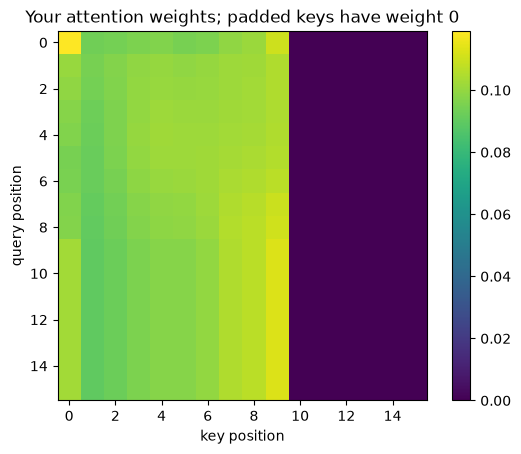

weight on padded keys: 0.0


In [22]:
# Use your function: Exercise 6.1
torch.manual_seed(3)
projection = torch.randn(7, 16)
tokens = (example_actions @ projection)[None, None]  # (1, 1, 16, 16): one batch row, one head
out, weights = scaled_dot_product_attention(tokens, tokens, tokens, example_pad[None])
plt.imshow(weights[0, 0], cmap="viridis")
plt.xlabel("key position")
plt.ylabel("query position")
plt.title("Your attention weights; padded keys have weight 0")
plt.colorbar()
plt.show()
print("weight on padded keys:", float(weights[0, 0][:, example_pad].sum()))

## Exercise 6.2 — Split and merge attention heads

**Purpose.** Several heads let a layer look at several relations at once. Each head works on its own slice of the features.

**Contract (shapes, units, masks).**

- `split_heads(x, n_heads)`: `x (B, T, D)` → `(B, H, T, D // H)`. Head `h` owns features `h*Dh : (h+1)*Dh`. Raise `ValueError` if `D` is not divisible by `H`.
- `merge_heads(x)`: `x (B, H, T, Dh)` → `(B, T, H * Dh)`. It exactly undoes `split_heads`.

**Method and source.** Multi-head attention splits the model width into `h` parts of size `d_model / h` — [Vaswani et al. 2017](https://arxiv.org/abs/1706.03762), section 3.2.2.

**Pointers.** First reshape the last axis into `(H, Dh)`. Then move the head axis in front of the position axis. Merging reverses both steps in the opposite order.

<details><summary>Detailed hint</summary>

`x.reshape(B, T, H, Dh).transpose(1, 2)` splits. `x.transpose(1, 2).reshape(B, T, H * Dh)` merges.
`transpose` returns a non-contiguous view, so use `reshape` (not `view`) when merging.

</details>

More behaviour checks for this exercise: `check_split_merge_heads` in [lesson06_checks.py](lesson06_checks.py).

In [20]:
# Implement: Exercise 6.2
def split_heads(x: torch.Tensor, n_heads: int) -> torch.Tensor:
    # (B, T, D) -> (B, H, T, D // H). Raise ValueError when D % H != 0.
    B, T, D = x.shape
    if D % n_heads != 0:
        raise ValueError("Not divisible")
    return x.reshape((B, T, n_heads, D // n_heads)).movedim(2, 1)


def merge_heads(x: torch.Tensor) -> torch.Tensor:
    # (B, H, T, Dh) -> (B, T, H * Dh).
    B, H, T, Dh = x.shape
    return x.movedim(1, 2).reshape((B, T, Dh * H))


# Check: Exercise 6.2
x = torch.arange(2 * 5 * 12, dtype=torch.float32).reshape(2, 5, 12)
heads = split_heads(x, 3)
assert heads.shape == (2, 3, 5, 4), "Expected (B, H, T, D // H)."
assert torch.equal(heads[1, 2, 3], x[1, 3, 8:12]), "Head 2 must own features 8..11."
assert torch.equal(heads[0, 0, :, 1], x[0, :, 1]), (
    "Head 0, feature 1 is feature 1 of every position."
)
merged = merge_heads(heads)
assert merged.shape == x.shape and torch.equal(merged, x), "merge_heads must undo split_heads."
assert torch.equal(merge_heads(split_heads(x, 1)), x) and torch.equal(
    merge_heads(split_heads(x, 12)), x
)
try:
    split_heads(x, 5)
except ValueError:
    pass
else:
    raise AssertionError("split_heads must raise ValueError when 12 is not divisible by 5.")
print("Exercise 6.2 passed")

# More behaviour checks: lesson06_checks.py, next to this notebook.
from lesson06_checks import check_split_merge_heads

check_split_merge_heads(split_heads, merge_heads)

Exercise 6.2 passed
✓ split_heads: heads[b, h, t] = x[b, t, h*Dh:(h+1)*Dh]
✓ merge_heads places head h at features h*Dh:(h+1)*Dh, and split undoes it
✓ handles non-contiguous inputs and keeps gradients
✓ raises ValueError when D is not divisible by H


**Use your function.** Split the example window's tokens into four heads and look at what each head receives.

In [23]:
# Use your function: Exercise 6.2
tokens = (example_actions @ projection)[None]  # (1, 16, 16)
four = split_heads(tokens, 4)  # (1, 4, 16, 4)
print("split shape:", tuple(four.shape))
print(
    "head 2 sees features 8..11 of position 0:",
    four[0, 2, 0].tolist() == tokens[0, 0, 8:12].tolist(),
)
print("merge restores the tokens:", bool(torch.equal(merge_heads(four), tokens)))

split shape: (1, 4, 16, 4)
head 2 sees features 8..11 of position 0: True
merge restores the tokens: True


## Exercise 6.3 — Multi-head attention

**Purpose.** Combine projections, heads and your Exercise 6.1 function into the layer that real models use.

**Contract (shapes, units, masks).**

- `attention` is a module with `q_proj`, `k_proj`, `v_proj`, `out_proj` (each `nn.Linear(D, D)`), `n_heads` (int), `dropout` (float) and the `training` flag.
- `query (B, Tq, D)`, `key (B, Tk, D)`, `value (B, Tk, D)`; `key_padding_mask (B, Tk)` with `True` = padding, or `None`.
- `attend` is a function with the contract of Exercise 6.1. **Call it; do not repeat its algebra here.**
- Pass `dropout_p = attention.dropout if attention.training else 0.0` to `attend`.
- Return `(output (B, Tq, D), weights (B, H, Tq, Tk))`.

**Method and source.** Section 3.2.2:

$$\operatorname{MultiHead}(Q,K,V)=\operatorname{Concat}\!\left(\text{head}_1,\dots,\text{head}_H\right)W^{O}, \qquad \text{head}_i=\operatorname{Attention}\!\left(QW_i^{Q},\,KW_i^{K},\,VW_i^{V}\right)$$

Where:
* $Q$, $K$, $V$ - the `query`, `key`, `value` inputs, each with width $D$.
* $H$ - number of heads (`attention.n_heads`); $i$ selects one head.
* $W_i^{Q}$, $W_i^{K}$, $W_i^{V}\in\mathbb{R}^{D\times D_h}$ - head $i$'s slice of `q_proj`, `k_proj`, `v_proj`, with $D_h=D/H$.
* $\operatorname{Concat}$ - joins the $H$ head outputs along the feature axis, back to width $D$.
* $W^{O}\in\mathbb{R}^{D\times D}$ - the output projection `out_proj`.

One wide linear layer followed by a split is the same as $H$ small matrices.

**Pointers.** Project the three inputs. Split each into heads. Call `attend`. Merge the heads. Apply the output projection. The query and the key/value inputs may have different lengths (cross-attention).

<details><summary>Detailed hint</summary>

```python
heads = attention.n_heads
q = split_heads(attention.q_proj(query), heads)
k = split_heads(attention.k_proj(key), heads)
v = split_heads(attention.v_proj(value), heads)
dropout_p = attention.dropout if attention.training else 0.0
out, weights = attend(q, k, v, key_padding_mask=key_padding_mask, dropout_p=dropout_p)
return attention.out_proj(merge_heads(out)), weights
```
Only the last line of the exercise is "new": the rest is the plumbing from Exercises 6.1 and 6.2.

</details>

More behaviour checks for this exercise: `check_multi_head_forward` in [lesson06_checks.py](lesson06_checks.py).

In [30]:
# Implement: Exercise 6.3
def multi_head_forward(
    attention: ProjectedAttention,
    query: torch.Tensor,
    key: torch.Tensor,
    value: torch.Tensor,
    key_padding_mask: torch.Tensor | None = None,
    attend: ScaledAttention = scaled_dot_product_attention,
) -> tuple[torch.Tensor, torch.Tensor]:
    # Use split_heads, attend (Exercise 6.1) and merge_heads. Return (output, weights).
    dropout_p = attention.dropout if attention.training else 0.0
    n_heads = attention.n_heads

    q_proj = split_heads(attention.q_proj(query), n_heads)
    k_proj = split_heads(attention.k_proj(key), n_heads)
    v_proj = split_heads(attention.v_proj(value), n_heads)

    out, weights = attend(q_proj, k_proj, v_proj, key_padding_mask, dropout_p)

    multihead = attention.out_proj(merge_heads(out))
    return multihead, weights


# Check: Exercise 6.3
D_, H_ = 16, 4
calls = []


def counting_attend(
    query: torch.Tensor,
    key: torch.Tensor,
    value: torch.Tensor,
    key_padding_mask: torch.Tensor | None = None,
    dropout_p: float = 0.0,
) -> tuple[torch.Tensor, torch.Tensor]:
    calls.append(tuple(query.shape))
    return scaled_dot_product_attention(query, key, value, key_padding_mask, dropout_p)


torch.manual_seed(2)
oracle = nn.MultiheadAttention(D_, H_, dropout=0.0, batch_first=True)
mine = ref.MultiHeadAttention(D_, H_, forward_fn=multi_head_forward, attend_fn=counting_attend)
ref.load_lerobot_attention(
    mine, oracle
)  # copies the oracle's weights into your module's four layers
x = torch.randn(3, 5, D_, requires_grad=True)
memory = torch.randn(3, 7, D_)
pad = torch.zeros(3, 7, dtype=torch.bool)
pad[1, 5:] = True
out = mine(x, memory, memory, pad)
assert calls == [(3, H_, 5, D_ // H_)], (
    f"Your function must call attend once with head-split queries; saw {calls}."
)
expected, w_oracle = oracle(x, memory, memory, key_padding_mask=pad)
close(out, expected, "cross-attention output differs from torch")
out.square().sum().backward()
x2 = x.detach().clone().requires_grad_(True)
oracle(x2, memory, memory, key_padding_mask=pad)[0].square().sum().backward()
close(x.grad, x2.grad, "gradient of the query input", atol=1e-4)
packed = torch.cat([mine.q_proj.weight.grad, mine.k_proj.weight.grad, mine.v_proj.weight.grad])
close(packed, oracle.in_proj_weight.grad, "gradient of the q/k/v projections", atol=1e-4)
assert mine.last_weights.shape == (3, H_, 5, 7), "weights must be (B, H, Tq, Tk)."
assert mine.last_weights[1, :, :, 5:].abs().sum() == 0, "padded memory keys must get weight 0."
self_out = mine(x, x, x)
close(self_out, oracle(x, x, x)[0], "self-attention output differs from torch")
print("Exercise 6.3 passed")

# More behaviour checks: lesson06_checks.py, next to this notebook.
from lesson06_checks import check_multi_head_forward

check_multi_head_forward(multi_head_forward)

Exercise 6.3 passed
✓ key and value are projected from their own inputs; attend gets split heads and the mask
✓ dropout_p is attention.dropout in training and 0 in eval
✓ returns the head weights from attend


**Use your function.** Run your module on the real window with and without the padding mask, and see which positions change.

In [31]:
# Use your function: Exercise 6.3
torch.manual_seed(4)
layer = ref.MultiHeadAttention(
    16, 4, forward_fn=multi_head_forward, attend_fn=scaled_dot_product_attention
)
tokens = (example_actions @ projection)[None]
with torch.no_grad():
    without_mask = layer(tokens, tokens, tokens)
    weights_open = layer.last_weights.clone()
    with_mask = layer(tokens, tokens, tokens, example_pad[None])
    weights_masked = layer.last_weights.clone()
difference = (with_mask - without_mask).abs().sum(-1)[0]
print(
    "output change at the first real positions:",
    [round(float(d), 3) for d in difference[~example_pad]][:6],
    "...",
)
print(
    "attention weight on padded keys, no mask:",
    round(float(weights_open[..., example_pad].sum()), 3),
)
print("attention weight on padded keys, with mask:", float(weights_masked[..., example_pad].sum()))

output change at the first real positions: [0.057, 0.057, 0.057, 0.057, 0.057, 0.057] ...
attention weight on padded keys, no mask: 24.149
attention weight on padded keys, with mask: 0.0


## Exercise 6.4 — Sinusoidal positional encoding

**Purpose.** Attention does not know the order of tokens. Add a fixed code that tells each position where it is.

**Contract (shapes, units, masks).**

- `sinusoidal_positions(num_positions, dimension)` returns a `float32` tensor `(num_positions, dimension)`; `dimension` is even.
- Row `p`, column `j`: angle `= p / 10000 ** (2 * (j // 2) / dimension)`. Even columns use `sin(angle)`; odd columns use `cos(angle)`.
- Positions count from 0, so row 0 is `[0, 1, 0, 1, …]`.

**Method and source.** [Vaswani et al. 2017](https://arxiv.org/abs/1706.03762), section 3.5:

$$PE_{p,\,2i}=\sin\!\left(\frac{p}{10000^{2i/d}}\right), \qquad PE_{p,\,2i+1}=\cos\!\left(\frac{p}{10000^{2i/d}}\right)$$

Where:
* $p$ - position, the row index, from 0 to `num_positions - 1`.
* $d$ - `dimension`, the number of columns.
* $i$ - index of a sine/cosine column pair, from 0 to $d/2-1$; columns $2i$ and $2i+1$ share one frequency.

ACT builds the same table for its posterior encoder.

**Pointers.** Build a column of positions and a row of column indices, divide, then fill the even and odd columns separately. Compute in `float64` and convert to `float32` at the end for the best match.

<details><summary>Detailed hint</summary>

```python
positions = torch.arange(num_positions, dtype=torch.float64)[:, None]
columns = torch.arange(dimension, dtype=torch.float64)[None, :]
angles = positions / 10000 ** (2 * (columns // 2) / dimension)
table = torch.zeros_like(angles)
table[:, 0::2] = angles[:, 0::2].sin()
table[:, 1::2] = angles[:, 1::2].cos()
return table.float()
```

</details>

More behaviour checks for this exercise: `check_sinusoidal_positions` in [lesson06_checks.py](lesson06_checks.py).

In [40]:
# Implement: Exercise 6.4
def sinusoidal_positions(num_positions: int, dimension: int) -> torch.Tensor:
    # Return a float32 tensor (num_positions, dimension): sin on even columns, cos on odd columns.
    d_enumerate = torch.tensor(list(range(dimension // 2)))
    p_enumerate = torch.tensor(list(range(num_positions)))

    d = d_enumerate.repeat(num_positions, 1)
    p = p_enumerate.repeat(dimension // 2, 1).T

    out = torch.zeros((num_positions, dimension))
    out[:, 0::2] = torch.sin(p / torch.pow(10_000, 2 * d / dimension))
    out[:, 1::2] = torch.cos(p / torch.pow(10_000, 2 * d / dimension))

    return out


# Check: Exercise 6.4
table = sinusoidal_positions(21, 32)
assert table.shape == (21, 32) and table.dtype == torch.float32, (
    "Expected a float32 (num_positions, dimension) table."
)
assert torch.equal(table[0, 0::2], torch.zeros(16)) and torch.equal(
    table[0, 1::2], torch.ones(16)
), "Position 0 must be [0, 1, 0, 1, ...]."
close(table[3, 0], torch.tensor(math.sin(3.0)), "row 3, column 0 is sin(3)", atol=1e-6)
close(
    table[3, 5],
    torch.tensor(math.cos(3 / 10000 ** (2 * 2 / 32))),
    "row 3, column 5 is cos(3 / 10000^(4/32))",
    atol=1e-6,
)
close(
    table,
    create_sinusoidal_pos_embedding(21, 32),
    "table differs from the pinned ACT table",
    atol=1e-6,
)
print("Exercise 6.4 passed")

# More behaviour checks: lesson06_checks.py, next to this notebook.
from lesson06_checks import check_sinusoidal_positions

check_sinusoidal_positions(sinusoidal_positions)

Exercise 6.4 passed
✓ small tables match the formula, including dimension 2 and one position
✓ large positions stay accurate
✓ each sin/cos column pair shares one frequency


**Use your function.** Look at the table. Nearby positions get similar codes; the dot product of two rows shows it.

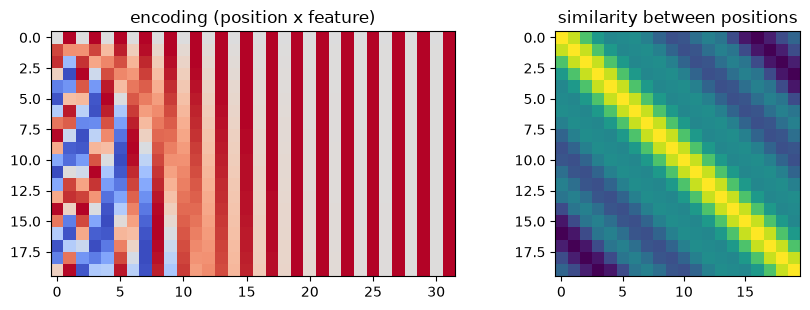

In [41]:
# Use your function: Exercise 6.4
table = sinusoidal_positions(20, 32)
similarity = table @ table.T
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].imshow(table, aspect="auto", cmap="coolwarm")
axes[0].set_title("encoding (position x feature)")
axes[1].imshow(similarity, cmap="viridis")
axes[1].set_title("similarity between positions")
plt.tight_layout()
plt.show()

## Exercise 6.5 — Encoder layer: residual, norm, feed-forward

**Purpose.** Wrap attention with the two residual blocks that make deep Transformers trainable. This is the block ACT stacks four times.

**Contract (shapes, units, masks).**

- `layer` is an `EncoderParts` module. Its attribute names follow PyTorch's `nn.TransformerEncoderLayer` and DETR's code, which ACT copies; the paper does not name them. Here `F` is the feed-forward width (`dim_feedforward`).

| Attribute | Type | What it does |
|---|---|---|
| `self_attn` | your multi-head attention (6.3–6.4) | `(query, key, value, key_padding_mask) -> (B, T, D)` |
| `linear1` | `nn.Linear(D, F)` | first feed-forward layer, widens each token to `F` |
| `linear2` | `nn.Linear(F, D)` | second feed-forward layer, back to `D` |
| `activation` | e.g. ReLU | nonlinearity between `linear1` and `linear2` |
| `norm1` | `nn.LayerNorm(D)` | normalisation for the attention sub-layer |
| `norm2` | `nn.LayerNorm(D)` | normalisation for the feed-forward sub-layer |
| `dropout` | `nn.Dropout` | inside the feed-forward, after `activation` |
| `dropout1` | `nn.Dropout` | on the attention output, before its residual add |
| `dropout2` | `nn.Dropout` | on the feed-forward output, before its residual add |
| `pre_norm` | `bool` | `True`: norm before each sub-layer; `False`: after the residual add |

  The `1`/`2` suffixes mean "first sub-layer (attention)" and "second sub-layer (feed-forward)". The three dropouts are separate modules so each can be switched off independently; with `dropout=0.0` (as in the checks) they are identities.
- `x (B, T, D)`; `pos_embed` is `None` or broadcastable to `(B, T, D)`; `key_padding_mask (B, T)` with `True` = padding.
- **Position rule:** add `pos_embed` to the *query and key only*, never to the value.
- Return `(B, T, D)`.
- **Where the norm goes.** Each of the two sub-layers (attention, then feed-forward) is a residual block: a *skip* path that carries `x` unchanged, and a *branch* that transforms it. The only difference between the two variants is whether the LayerNorm sits on the branch's input or after the two paths are added.

  Post-norm (`pre_norm=False`, ACT's default, the original Transformer): normalise **after** the residual add, so the sum is normalised.
  $$h = \mathrm{LN}_1\big(x + \mathrm{Drop}_1(\mathrm{Attn}(x))\big), \qquad y = \mathrm{LN}_2\big(h + \mathrm{Drop}_2(\mathrm{FF}(h))\big)$$

  Pre-norm (`pre_norm=True`): normalise **only the branch input**, at the start of the branch. The skip path carries the *un-normalised* `x`, and nothing is normalised after the add.
  $$h = x + \mathrm{Drop}_1\big(\mathrm{Attn}(\mathrm{LN}_1(x))\big), \qquad y = h + \mathrm{Drop}_2\big(\mathrm{FF}(\mathrm{LN}_2(h))\big)$$

  Where:
  - $x$ is the layer input `(B, T, D)`; $h$ is the output of the attention block; $y$ is the layer output.
  - $\mathrm{LN}_1$, $\mathrm{LN}_2$ are `layer.norm1`, `layer.norm2`; $\mathrm{Drop}_1$, $\mathrm{Drop}_2$ are `layer.dropout1`, `layer.dropout2`.
  - $\mathrm{Attn}(z)$ is `layer.self_attn(z + pos, z + pos, z, key_padding_mask)`: in pre-norm, $z = \mathrm{LN}_1(x)$ is used for query, key **and** value, and the position is added after the norm.
  - $\mathrm{FF}(z)$ is `linear2(dropout(activation(linear1(z))))`.

  Why it matters: in pre-norm the skip path is a clean identity from input to output, which makes deep stacks easier to train; the price is that the output is not normalised, so a pre-norm encoder adds one final LayerNorm after the last layer (`TransformerEncoder` does this for you, not this function).
- `ff(x) = linear2(dropout(activation(linear1(x))))`. Apply `dropout1` to the attention output and `dropout2` to the feed-forward output before each residual add.

**Method and source.** Encoder layer — [Vaswani et al. 2017](https://arxiv.org/abs/1706.03762), sections 3.1 and 3.3. ACT's `ACTEncoderLayer` (pinned) adds the position to the query and key only and uses post-norm by default.

**Pointers.** Keep the input in a `skip` variable before each sub-layer. Decide where the norm goes from `layer.pre_norm`. Call `layer.self_attn(q, k, value, key_padding_mask)` with the position added to `q` and `k`.

<details><summary>Detailed hint</summary>

Post-norm pattern (default):
```python
skip = x
qk = x if pos_embed is None else x + pos_embed
x = layer.self_attn(qk, qk, x, key_padding_mask)
x = layer.norm1(skip + layer.dropout1(x))
skip = x
x = layer.linear2(layer.dropout(layer.activation(layer.linear1(x))))
x = layer.norm2(skip + layer.dropout2(x))
```
Pre-norm moves each `norm` in front of its sub-layer and removes it after the add. Write both branches with `if layer.pre_norm:`.

</details>

More behaviour checks for this exercise: `check_encoder_layer_forward` in [lesson06_checks.py](lesson06_checks.py).

In [46]:
# Implement: Exercise 6.5
def encoder_layer_forward(
    layer: EncoderParts,
    x: torch.Tensor,
    pos_embed: torch.Tensor | None = None,
    key_padding_mask: torch.Tensor | None = None,
) -> torch.Tensor:
    # Attention then feed-forward, each with a residual connection and a norm. Position on q and k only.
    if layer.pre_norm:
        skip = x
        x = layer.norm1(x)
        qk = x + pos_embed if pos_embed is not None else x
        x = layer.self_attn(qk, qk, x, key_padding_mask)
        x = skip + layer.dropout1(x)
        skip = x
        x = layer.norm2(x)
        # x -> linear1 -> activation -> dropout -> linear2
        x = layer.linear2(layer.dropout(layer.activation(layer.linear1(x))))
        x = skip + layer.dropout2(x)
    else:
        skip = x
        qk = x + pos_embed if pos_embed is not None else x
        x = layer.self_attn(qk, qk, x, key_padding_mask)
        x = layer.norm1(skip + layer.dropout1(x))
        skip = x
        # x -> linear1 -> activation -> dropout -> linear2
        x = layer.linear2(layer.dropout(layer.activation(layer.linear1(x))))
        x = layer.norm2(skip + layer.dropout2(x))

    return x


# Check: Exercise 6.5
D_, H_, FF_ = 16, 4, 32


def config(pre: bool) -> ACTConfig:
    return ACTConfig(
        dim_model=D_,
        n_heads=H_,
        dim_feedforward=FF_,
        dropout=0.0,
        pre_norm=pre,
        chunk_size=4,
        n_action_steps=4,
        input_features={},
        output_features={},
    )


pad = torch.zeros(3, 6, dtype=torch.bool)
pad[1, 4:] = True
pad[2, 2:] = True
valid = ~pad[..., None]
for pre in (False, True):
    torch.manual_seed(5)
    oracle = ACTEncoderLayer(config(pre)).eval()
    mine = ref.EncoderLayer(
        D_,
        H_,
        FF_,
        pre_norm=pre,
        forward_fn=encoder_layer_forward,
        attention_forward_fn=multi_head_forward,
        attend_fn=scaled_dot_product_attention,
    ).eval()
    ref.load_lerobot_encoder_layer(mine, oracle)
    x = torch.randn(3, 6, D_, requires_grad=True)
    pos = torch.randn(1, 6, D_)
    out = mine(x, pos, pad)
    expected = oracle(
        x.transpose(0, 1), pos_embed=pos.expand(3, -1, -1).transpose(0, 1), key_padding_mask=pad
    ).transpose(0, 1)
    close(
        out * valid, expected * valid, f"layer output (pre_norm={pre}) differs from ACTEncoderLayer"
    )
    (out * valid).square().sum().backward()
    x2 = x.detach().clone().requires_grad_(True)
    (
        oracle(
            x2.transpose(0, 1),
            pos_embed=pos.expand(3, -1, -1).transpose(0, 1),
            key_padding_mask=pad,
        ).transpose(0, 1)
        * valid
    ).square().sum().backward()
    close(x.grad, x2.grad, f"input gradient (pre_norm={pre})", atol=1e-4)
    close(
        mine.linear1.weight.grad,
        oracle.linear1.weight.grad,
        f"feed-forward gradient (pre_norm={pre})",
        atol=1e-4,
    )
    assert not torch.allclose(mine(x, None, pad) * valid, out.detach() * valid, atol=1e-3), (
        "The position must change the result."
    )
    moved = x.detach().clone()
    moved[pad] = 100.0
    close(
        mine(moved, pos, pad) * valid,
        out.detach() * valid,
        f"padded values must not change real outputs (pre_norm={pre})",
        atol=1e-4,
    )
print("Exercise 6.5 passed")

# More behaviour checks: lesson06_checks.py, next to this notebook.
from lesson06_checks import check_encoder_layer_forward

check_encoder_layer_forward(encoder_layer_forward)

Exercise 6.5 passed
✓ post-norm and pre-norm: exact placement of norms, residuals and the three dropouts
✓ pos_embed is added to the query and key only; the mask reaches self_attn
✓ pos_embed=None and key_padding_mask=None are handled


**Use your function.** Wire all your functions into a two-layer encoder and compare it, output and gradient, with the installed ACT encoder stack on real action tokens.

In [47]:
# Use your function: Exercise 6.5
D_, H_, FF_ = 16, 4, 32
config = ACTConfig(
    dim_model=D_,
    n_heads=H_,
    dim_feedforward=FF_,
    n_encoder_layers=2,
    dropout=0.0,
    chunk_size=4,
    n_action_steps=4,
    input_features={},
    output_features={},
)
torch.manual_seed(6)
pinned = ACTEncoder(config).eval()
yours = ref.TransformerEncoder(
    2,
    D_,
    H_,
    FF_,
    forward_fn=encoder_layer_forward,
    attention_forward_fn=multi_head_forward,
    attend_fn=scaled_dot_product_attention,
).eval()
ref.load_lerobot_encoder(yours, pinned)
batch_tokens = torch.stack([(VALID["action"][i] @ projection) for i in range(8)]).requires_grad_(
    True
)
batch_pad = VALID["action_is_pad"][:8]
positions = sinusoidal_positions(16, D_)[None]
out = yours(batch_tokens, positions, batch_pad)
theirs_input = batch_tokens.detach().clone().requires_grad_(True)
theirs = pinned(
    theirs_input.transpose(0, 1),
    pos_embed=positions.expand(8, -1, -1).transpose(0, 1),
    key_padding_mask=batch_pad,
).transpose(0, 1)
real = ~batch_pad[..., None]
(out * real).sum().backward()
(theirs * real).sum().backward()
print("largest output difference at real positions:", float(((out - theirs).abs() * real).max()))
print(
    "largest input-gradient difference:", float((batch_tokens.grad - theirs_input.grad).abs().max())
)

largest output difference at real positions: 0.0
largest input-gradient difference: 3.552713678800501e-15


/tmp/ipykernel_388327/112588711.py:41: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  print("largest output difference at real positions:", float(((out - theirs).abs() * real).max()))


## Experiment — where does the padding mask matter?

**Question.** Does the key padding mask change what an encoder learns from real padded action chunks, and does it change how the model reacts to padded values?

**Task (real data).** Input: a 16-step action window from a real demonstration; padded steps repeat the last real action. Target: the mean of the *real* (not padded) actions, 7 values. The pooled output uses only real positions in every run, so any difference comes from attention, not from pooling.

**Fixed for every trial (do not change).** Windows: `TRAIN` and `VALID` above (validation episodes are never used for updates). Seed `0` for weights, seed `1` for batch draws. **150 updates**, batch 64, AdamW with learning rate `2e-3`. Model width 32. Your own functions from Exercises 6.1–6.5 are used inside every encoder layer.

**Allowed changes (per trial).** `mask` (pass the padding mask to attention or not), `pos` (add sinusoidal positions or not), `layers` (1–3), `heads` (1, 2 or 4).

**Measures.** `val_mse_padded`: mean squared error on validation windows that contain padding. `val_mse_all`: all validation windows. `pad_sensitivity`: mean absolute change of the output when the padded steps are replaced by random values (a robust model gives about 0).

**Prediction first.** Before running anything, write two sentences: which arm do you expect to be worst on `pad_sensitivity`, and will `val_mse_all` change much? Edit the next cell.

**Keep failed trials.** Every trial is appended to `TRIALS` as a `TrialResult` dict (from `vla_lab.teaching.records`): `config` holds the trial's `TrialConfig` settings, `status` is `"ok"` or `"failed: <error>"`, and the measures above are extra keys of the same row. Do not delete or overwrite rows; a result that does not improve is a valid result.

In [ ]:
# Run this cell to start the larger training experiment.


In [ ]:
# Write your prediction here (one cell, before you run the trials).
# Write your prediction in the Markdown cell above before you run the experiment.


In [48]:
# Supplied: trial table helper
import time

import pandas as pd


def show_trials(trials: Sequence[TrialResult], columns: Sequence[str]) -> pd.DataFrame:
    """Print every trial that was run, including failed ones, and return a table."""
    table = pd.DataFrame(
        [{**t["config"], **{c: t.get(c) for c in columns}, "status": t["status"]} for t in trials]
    )
    print(table.to_string(index=False, float_format=lambda v: f"{v:.4g}"))
    return table

In [49]:
# Supplied: the experiment harness. It calls YOUR functions through the encoder hooks.
STEPS, BATCH, LR, SEED_WEIGHTS, SEED_BATCH, WIDTH = 150, 64, 2e-3, 0, 1, 32


def masked_mean(values: torch.Tensor, is_pad: torch.Tensor) -> torch.Tensor:
    keep = (~is_pad).unsqueeze(-1).float()
    return (values * keep).sum(1) / keep.sum(1).clamp_min(1)


class ChunkEncoder(nn.Module):
    """Linear input layer -> your encoder layers -> mean over real positions -> linear output."""

    def __init__(self, layers: int = 2, heads: int = 4, pos: bool = True) -> None:
        super().__init__()
        self.inp = nn.Linear(7, WIDTH)
        self.encoder = ref.TransformerEncoder(
            layers,
            WIDTH,
            heads,
            2 * WIDTH,
            forward_fn=encoder_layer_forward,
            attention_forward_fn=multi_head_forward,
            attend_fn=scaled_dot_product_attention,
        )
        self.out = nn.Linear(WIDTH, 7)
        self.register_buffer(
            "positions", sinusoidal_positions(16, WIDTH)[None] if pos else torch.zeros(1, 16, WIDTH)
        )

    def forward(
        self, actions: torch.Tensor, is_pad: torch.Tensor | None, use_mask: bool = True
    ) -> torch.Tensor:
        hidden = self.encoder(self.inp(actions), self.positions, is_pad if use_mask else None)
        return self.out(masked_mean(hidden, is_pad))


BASELINE = {"mask": True, "pos": True, "layers": 2, "heads": 4}
TRIALS = []


def run_trial(config: TrialConfig) -> dict[str, float | int]:
    started = time.perf_counter()
    torch.manual_seed(SEED_WEIGHTS)
    model = ChunkEncoder(config["layers"], config["heads"], config["pos"])
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR)
    draws = torch.Generator().manual_seed(SEED_BATCH)
    for _ in range(STEPS):
        pick = torch.randint(0, len(TRAIN["action"]), (BATCH,), generator=draws)
        actions, pad = TRAIN["action"][pick], TRAIN["action_is_pad"][pick]
        loss = (model(actions, pad, config["mask"]) - masked_mean(actions, pad)).square().mean()
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        has_pad = VALID["action_is_pad"].any(1)
        a, p = VALID["action"][has_pad], VALID["action_is_pad"][has_pad]
        out = model(a, p, config["mask"])
        noise = torch.randn(a.shape, generator=torch.Generator().manual_seed(5)) * 3
        shaken = torch.where(p.unsqueeze(-1), noise, a)
        all_a, all_p = VALID["action"], VALID["action_is_pad"]
        return {
            "val_mse_padded": (out - masked_mean(a, p)).square().mean().item(),
            "val_mse_all": (model(all_a, all_p, config["mask"]) - masked_mean(all_a, all_p))
            .square()
            .mean()
            .item(),
            "pad_sensitivity": (model(shaken, p, config["mask"]) - out).abs().mean().item(),
            "seconds": time.perf_counter() - started,
        }


def record(config: TrialConfig) -> None:
    """Run one trial and append it to TRIALS. Errors are kept as failed trials."""
    config = {**BASELINE, **config}
    try:
        TRIALS.append({"config": config, "status": "ok", **run_trial(config)})
    except Exception as error:  # a failed trial is evidence too
        TRIALS.append({"config": config, "status": f"failed: {type(error).__name__}: {error}"})


record(BASELINE)
COLUMNS = ["val_mse_padded", "val_mse_all", "pad_sensitivity", "seconds"]
show_trials(TRIALS, COLUMNS);

 mask  pos  layers  heads  val_mse_padded  val_mse_all  pad_sensitivity  seconds status
 True True       2      4       0.0003198    0.0003357                0    1.011     ok


**Your trials.** Add at least two trials that change one setting each. List them in `MY_TRIALS`, then run the next cell. You may run more than once; every run adds rows.

In [51]:
# Implement: choose your trials (each dict changes only the settings you name).
MY_TRIALS = [
    # {"mask": False, "pos": True, "layers": 2, "heads": 4},
    # {"mask": True, "pos": False, "layers": 2, "heads": 4},
    # {"mask": True, "pos": False, "layers": 8, "heads": 4},
    # {"mask": True, "pos": False, "layers": 2, "heads": 16},
    {"mask": True, "pos": True, "layers": 8, "heads": 4},
    {"mask": True, "pos": True, "layers": 2, "heads": 16},
]
for trial in MY_TRIALS:
    record(trial)
show_trials(TRIALS, COLUMNS);

 mask   pos  layers  heads  val_mse_padded  val_mse_all  pad_sensitivity  seconds status
 True  True       2      4       0.0003198    0.0003357                0    1.011     ok
False  True       2      4        0.001136    0.0004827           0.1898   0.9931     ok
 True False       2      4       0.0003231    0.0003332                0     1.03     ok
 True False       8      4       0.0002847    0.0003139                0     3.75     ok
 True False       2     16        0.000276    0.0003069                0    1.288     ok
 True  True       8      4       0.0002935    0.0003288                0    3.756     ok
 True  True       2     16       0.0002831    0.0003227                0    1.327     ok


In [52]:
# Check: the protocol was followed.
assert TRIALS[0]["config"] == BASELINE, "The first trial must be the baseline."
assert len(TRIALS) >= 3, "Run the baseline and at least two trials of your own."
assert all(t["status"] == "ok" or t["status"].startswith("failed") for t in TRIALS)
assert all(set(t["config"]) == set(BASELINE) for t in TRIALS), (
    "Only mask, pos, layers and heads may change."
)
ok = [t for t in TRIALS if t["status"] == "ok"]
assert all(torch.isfinite(torch.tensor([t[c] for c in COLUMNS])).all() for t in ok), (
    "Every measure must be finite."
)
print(
    f"{len(TRIALS)} trials kept ({len(ok)} ok). Budget: {STEPS} updates, batch {BATCH}, seeds {SEED_WEIGHTS}/{SEED_BATCH}."
)

7 trials kept (7 ok). Budget: 150 updates, batch 64, seeds 0/1.


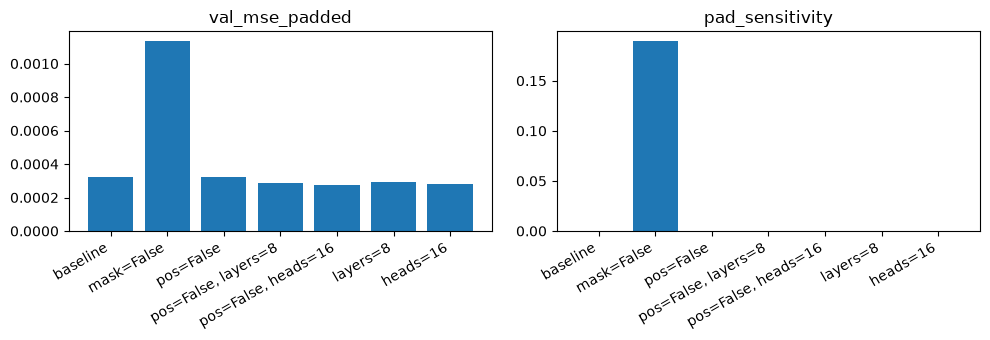

In [53]:
# Use your function: plot every trial (nothing is hidden or averaged away)
labels = [
    ", ".join(f"{k}={v}" for k, v in t["config"].items() if v != BASELINE[k]) or "baseline"
    for t in TRIALS
    if t["status"] == "ok"
]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for axis, column in zip(axes, ["val_mse_padded", "pad_sensitivity"], strict=True):
    axis.bar(range(len(labels)), [t[column] for t in TRIALS if t["status"] == "ok"])
    axis.set_xticks(range(len(labels)))
    axis.set_xticklabels(labels, rotation=30, ha="right")
    axis.set_title(column)
plt.tight_layout()
plt.show()

**Explain (2–4 sentences, edit this cell).** Which trial had the largest `pad_sensitivity`, and why does the mask change it? Did your prediction hold? One limit of this evidence: the padded steps in training always repeat the last real action. What would you test next?

*Optional extension:* repeat the best two arms with a different batch seed (`SEED_BATCH`) and report the spread. Keep both sets of rows.

## Optional: your layers on the real ACT posterior encoder

This section loads the **prepared** ACT checkpoint `act-bowl-plate-probe-200` from local files and copies its posterior-encoder weights into *your* layers. It then feeds real, padded action chunks to both encoders. This shows that your code reproduces a real trained block. It is not a training run and it says nothing about robot success. The workload is 8 video frames. No download starts. Run the next cell to run it.

In [54]:
from lerobot.policies.act import ACTPolicy

from vla_lab.teaching.act_model import load_act_samples

checkpoint = DATA / "runs/act-bowl-plate-probe-200/checkpoint-000200"
if not (checkpoint / "model.safetensors").is_file():
    raise FileNotFoundError(f"Prepared ACT checkpoint missing: {checkpoint}")
config = ACTConfig.from_pretrained(checkpoint, local_files_only=True)
config.device = "cpu"
pinned = ACTPolicy.from_pretrained(
    checkpoint, config=config, strict=True, local_files_only=True
).model.eval()
width = config.dim_model
yours = ref.TransformerEncoder(
    config.n_vae_encoder_layers,
    width,
    config.n_heads,
    config.dim_feedforward,
    forward_fn=encoder_layer_forward,
    attention_forward_fn=multi_head_forward,
    attend_fn=scaled_dot_product_attention,
).eval()
ref.load_lerobot_encoder(yours, pinned.vae_encoder)
samples = load_act_samples(
    CONFIGS, DATA, "bowl_plate", "validation", count=8, chunk_size=config.chunk_size, image_size=32
)
with torch.no_grad():
    cls = pinned.vae_encoder_cls_embed.weight[None].expand(8, -1, -1)
    tokens = torch.cat(
        [
            cls,
            pinned.vae_encoder_robot_state_input_proj(samples["observation.state"])[:, None],
            pinned.vae_encoder_action_input_proj(samples["action"]),
        ],
        dim=1,
    )
    mask = torch.cat([torch.zeros(8, 2, dtype=torch.bool), samples["action_is_pad"]], dim=1)
    pos = pinned.vae_encoder_pos_enc
    theirs = pinned.vae_encoder(
        tokens.transpose(0, 1), pos_embed=pos.transpose(0, 1), key_padding_mask=mask
    ).transpose(0, 1)
    mine = yours(tokens, pos, mask)
    real = ~mask[..., None]
    print("padded steps in these chunks:", int(samples["action_is_pad"].sum()))
    print("largest difference at real positions:", float(((mine - theirs).abs() * real).max()))
    shaken = tokens.clone()
    shaken[:, 2:][samples["action_is_pad"]] = 25.0
    print(
        "change when padded tokens are replaced:",
        float(((yours(shaken, pos, mask) - mine).abs() * real).max()),
    )

Loading weights from local directory
padded steps in these chunks: 36
largest difference at real positions: 9.5367431640625e-07
change when padded tokens are replaced: 0.0


## What you built

- `scaled_dot_product_attention`, `split_heads`/`merge_heads`, `multi_head_forward`, `sinusoidal_positions` and `encoder_layer_forward`, checked for output **and** gradient against torch and the pinned ACT blocks.
- A padding rule you tested three ways: weights, gradients and downstream predictions.

**Next:** Lesson 7 adds the decoder: self-attention, cross-attention, feed-forward. Starting in Lesson 7, you can import the package versions of these five functions (`vla_lab.teaching.attention`); your notebook answers are not needed to continue.